# Comparación de tres formulaciones: dos particiones de CO₂
**Ensayo principal: CO₂ calibrado con LAB019–021 y holdout LAB016–018.**
**Ensayo inverso: CO₂ calibrado con LAB016–018 y holdout LAB019–021.**

Este notebook sólo carga parámetros: no optimiza. Las figuras de CO₂ se muestran separadas para ambas particiones; los títulos de cada panel indican su función. Las tres formulaciones se han ajustado al mismo objetivo de medianas horarias del sensor crudo, con igual ponderación por fermentación.

**La partición química es distinta y no cambia:** química calibrada en LAB004–009; LAB019–021 son holdout químico. En el ensayo principal LAB019–021 es calibración de CO₂ y, a la vez, holdout químico; no es un holdout conjunto del modelo completo.

**Figuras:** primero CO₂ emitido, después G+F de calibración química y holdout químico, estados químicos en holdout y diagnósticos de depósito/transferencia para cada ajuste de CO₂. En estos diagnósticos las curvas son predicciones internas antes de la ganancia de observación; sólo el punto inicial Cd es medido. En la comparación con el sensor la predicción incluye esa ganancia.

La solubilidad de los modelos nuevos sigue PROVISIONAL. Cd0 de LAB021 es provisional y en LAB016–018 se asume cero por falta de medición. El histórico conserva ecuaciones y theta_nv2; sus coeficientes de CO₂ se reajustan para cada partición sin alterar los ajustes históricos originales. No se elige un modelo sólo por el error de calibración.


Las figuras de CO₂ emitido unen con una línea las medianas horarias usadas para calibrar y evaluar, con la misma cobertura del objetivo y eje Y automático; no muestran la RAW densa ni la señal filtrada GUI.

G+F se compara con la medición conjunta GF_g_l, aunque falte G o F individual. YAN incluye las filas NUT con medición numérica. La muestra inicial se muestra en las figuras y se excluye únicamente del error de predicción posterior. No se modifican datos ni parámetros.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/sources.csv').exists())
sys.dont_write_bytecode=True
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
assert Path(sys.prefix).name.lower()=='fermentation'


In [2]:
from wine_fermentation.comparison import run_both,PRIMARY_TRAINING,chemical_observations
from IPython.display import Markdown
experiments=run_both(ROOT,fit_gas=False)
result=experiments[PRIMARY_TRAINING]
combined=pd.concat([res['metrics'] for res in experiments.values()],ignore_index=True)
for key,res in experiments.items():
    display(Markdown('## CO₂ '+('principal' if key==PRIMARY_TRAINING else 'inverso')+': '+key))
    display(res['metrics'])
    display(pd.DataFrame(res['gas_fits']).T)
display(Markdown('## Media de RMSE por fermentación [g/(L·h)] · calibración y holdout separados'))
display(combined.groupby(['model','training','split']).RMSE.mean().unstack(['training','split']))
paired=combined.pivot(index=['model','lab'],columns='training',values='RMSE')
paired['delta_RMSE_principal_menos_inversa']=paired['train_019_021']-paired['train_016_018']
paired['rol_principal']=['Calibración CO₂' if lab in result['training_labs'] else 'Holdout CO₂' for _,lab in paired.index]
display(Markdown('## Mismo LAB, dos ajustes · delta negativo = menor RMSE con el ajuste principal; el rol del LAB cambia'))
display(paired)
display(Markdown('## Holdout químico LAB019–021 · parámetros químicos idénticos en ambos ensayos de CO₂'))
display(result['chemical_metrics'])

sample_checks=[]
for lab in ('LAB019','LAB020','LAB021'):
    for state in ('GF','N'):
        plotted=chemical_observations(result['V'].chem,lab,state)
        scored=chemical_observations(result['V'].chem,lab,state,after_initial=True)
        col='GF_g_l' if state=='GF' else 'N_kg_m3'
        source=result['V'].chem.loc[result['V'].chem.lab.eq(lab)]
        assert len(plotted)==int(source[col].notna().sum())
        measured_nut=source.loc[source.is_NUT & source[col].notna(),'sample']
        assert set(measured_nut).issubset(set(plotted['sample']))
        for model in ('historical','without_transporters','with_transporters'):
            row=result['chemical_metrics'].query('model==@model and lab==@lab and state==@state')
            assert len(row)==1 and int(row.n.iloc[0])==len(scored)
        sample_checks.append(dict(lab=lab,variable=state,observaciones_en_figura=len(plotted),
            observaciones_en_metricas=len(scored),muestras_NUT_incluidas=len(measured_nut)))
display(Markdown('## Cobertura de las muestras de G+F y YAN'))
display(pd.DataFrame(sample_checks))


## CO₂ principal: train_019_021

,model,training,lab,n,split,RMSE,bias
0,historical,train_019_021,LAB016,152,gas_validation,0.142676,0.020079
1,historical,train_019_021,LAB017,152,gas_validation,0.109835,0.005824
2,historical,train_019_021,LAB018,152,gas_validation,0.107606,0.007321
3,historical,train_019_021,LAB019,184,gas_training,0.140971,0.017589
4,historical,train_019_021,LAB020,184,gas_training,0.049503,-0.000354
5,historical,train_019_021,LAB021,184,gas_training,0.190718,-0.032651
6,without_transporters,train_019_021,LAB016,152,gas_validation,0.152938,-0.000703
7,without_transporters,train_019_021,LAB017,152,gas_validation,0.165135,-0.034674
8,without_transporters,train_019_021,LAB018,152,gas_validation,0.155629,-0.013265
9,without_transporters,train_019_021,LAB019,184,gas_training,0.119431,0.014843


,kCO2_release_h,CO2sat_scale,matrix_gain,success,message,training,training_labs,holdout_labs,objective,nfev,...,initial_parameters,parameter_bounds,target,weighting,chemical_parameters,historical_equations_unchanged,solubility_status,Cd0_unmeasured,kLa,gain
historical,1.229635,2.5,0.836671,True,`ftol` termination condition is satisfied.,train_019_021,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",0.058697,7,...,"{'kCO2_release_h': 0.4, 'CO2sat_scale': 1.0, '...","{'kCO2_release_h': [0.03, 25.0], 'CO2sat_scale...",hourly_median_raw_g_l_h,equal_lab_mean_squared_error,theta_nv2,True,historical_unchanged,0 assumed for LAB016-018,NaN,NaN
without_transporters,NaN,NaN,NaN,True,`gtol` termination condition is satisfied.,train_019_021,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",0.092432,10,...,"{'kLa': 1.0, 'gain': 0.7}","{'kLa': [0.01, 20.0], 'gain': [0.05, 3.0]}",hourly_median_raw_g_l_h,equal_lab_mean_squared_error,unchanged chemical fit.json,False,provisional_inherited_correlation,0 assumed for LAB016-018,20.0,0.624818
with_transporters,NaN,NaN,NaN,True,`gtol` termination condition is satisfied.,train_019_021,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",0.100425,8,...,"{'kLa': 1.0, 'gain': 0.7}","{'kLa': [0.01, 20.0], 'gain': [0.05, 3.0]}",hourly_median_raw_g_l_h,equal_lab_mean_squared_error,unchanged chemical fit.json,False,provisional_inherited_correlation,0 assumed for LAB016-018,19.999971,0.604172


## CO₂ inverso: train_016_018

,model,training,lab,n,split,RMSE,bias
0,historical,train_016_018,LAB016,152,gas_training,0.090438,0.003987
1,historical,train_016_018,LAB017,152,gas_training,0.077464,-0.010799
2,historical,train_016_018,LAB018,152,gas_training,0.075468,-0.008743
3,historical,train_016_018,LAB019,184,gas_validation,0.093162,0.006521
4,historical,train_016_018,LAB020,184,gas_validation,0.045171,-0.010291
5,historical,train_016_018,LAB021,184,gas_validation,0.242784,-0.041553
6,without_transporters,train_016_018,LAB016,152,gas_training,0.145655,0.013651
7,without_transporters,train_016_018,LAB017,152,gas_training,0.158045,-0.020615
8,without_transporters,train_016_018,LAB018,152,gas_training,0.152369,0.001421
9,without_transporters,train_016_018,LAB019,184,gas_validation,0.107860,0.026564


,kCO2_release_h,CO2sat_scale,matrix_gain,success,message,training,training_labs,holdout_labs,objective,nfev,...,initial_parameters,parameter_bounds,target,weighting,chemical_parameters,historical_equations_unchanged,solubility_status,Cd0_unmeasured,kLa,gain
historical,0.175685,2.5,0.802053,True,`ftol` termination condition is satisfied.,train_016_018,"[LAB016, LAB017, LAB018]","[LAB019, LAB020, LAB021]",0.019875,6,...,"{'kCO2_release_h': 0.4, 'CO2sat_scale': 1.0, '...","{'kCO2_release_h': [0.03, 25.0], 'CO2sat_scale...",hourly_median_raw_g_l_h,equal_lab_mean_squared_error,theta_nv2,True,historical_unchanged,0 assumed for LAB016-018,NaN,NaN
without_transporters,NaN,NaN,NaN,True,`ftol` termination condition is satisfied.,train_016_018,"[LAB016, LAB017, LAB018]","[LAB019, LAB020, LAB021]",0.06941,13,...,"{'kLa': 1.0, 'gain': 0.7}","{'kLa': [0.01, 20.0], 'gain': [0.05, 3.0]}",hourly_median_raw_g_l_h,equal_lab_mean_squared_error,unchanged chemical fit.json,False,provisional_inherited_correlation,0 assumed for LAB016-018,0.221365,0.65456
with_transporters,NaN,NaN,NaN,True,`ftol` termination condition is satisfied.,train_016_018,"[LAB016, LAB017, LAB018]","[LAB019, LAB020, LAB021]",0.060315,16,...,"{'kLa': 1.0, 'gain': 0.7}","{'kLa': [0.01, 20.0], 'gain': [0.05, 3.0]}",hourly_median_raw_g_l_h,equal_lab_mean_squared_error,unchanged chemical fit.json,False,provisional_inherited_correlation,0 assumed for LAB016-018,0.431455,0.664575


... (4 outputs left out)

## Holdout químico LAB019–021 · parámetros químicos idénticos en ambos ensayos de CO₂

,model,lab,state,n,RMSE,bias
0,historical,LAB019,X,10,0.333142,0.075391
1,historical,LAB019,N,12,0.044021,-0.025393
2,historical,LAB019,G,7,2.599255,1.235900
3,historical,LAB019,F,7,3.519361,0.710425
4,historical,LAB019,E,5,11.790213,10.719748
5,historical,LAB019,GF,11,5.859407,-1.263900
6,historical,LAB020,X,10,0.561107,-0.264664
7,historical,LAB020,N,12,0.009056,-0.003044
8,historical,LAB020,G,6,8.833357,7.621429
9,historical,LAB020,F,6,5.428427,3.229307


## Cobertura de las muestras de G+F y YAN

,lab,variable,observaciones_en_figura,observaciones_en_metricas,muestras_NUT_incluidas
0,LAB019,GF,12,11,0
1,LAB019,N,13,12,1
2,LAB020,GF,12,11,0
3,LAB020,N,13,12,1
4,LAB021,GF,10,9,0
5,LAB021,N,13,12,1


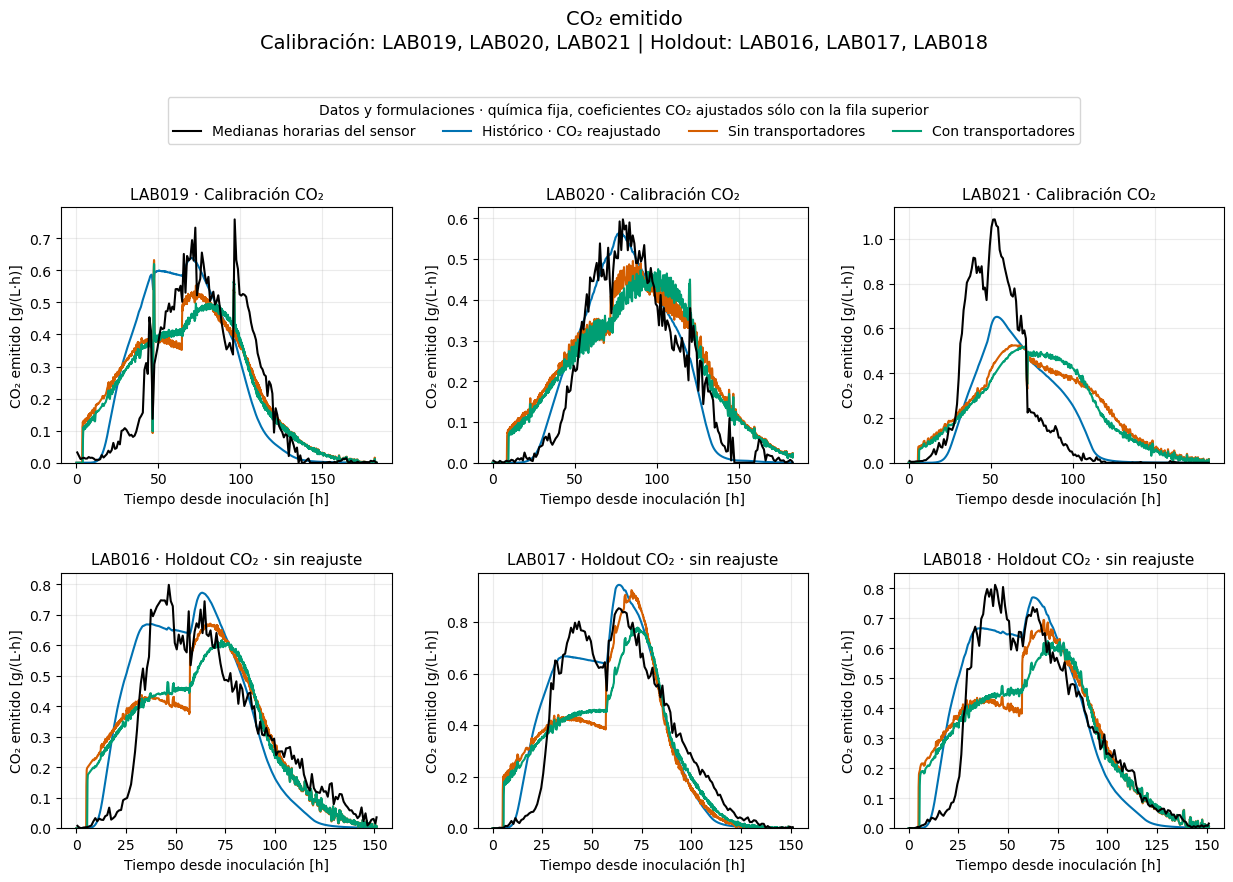

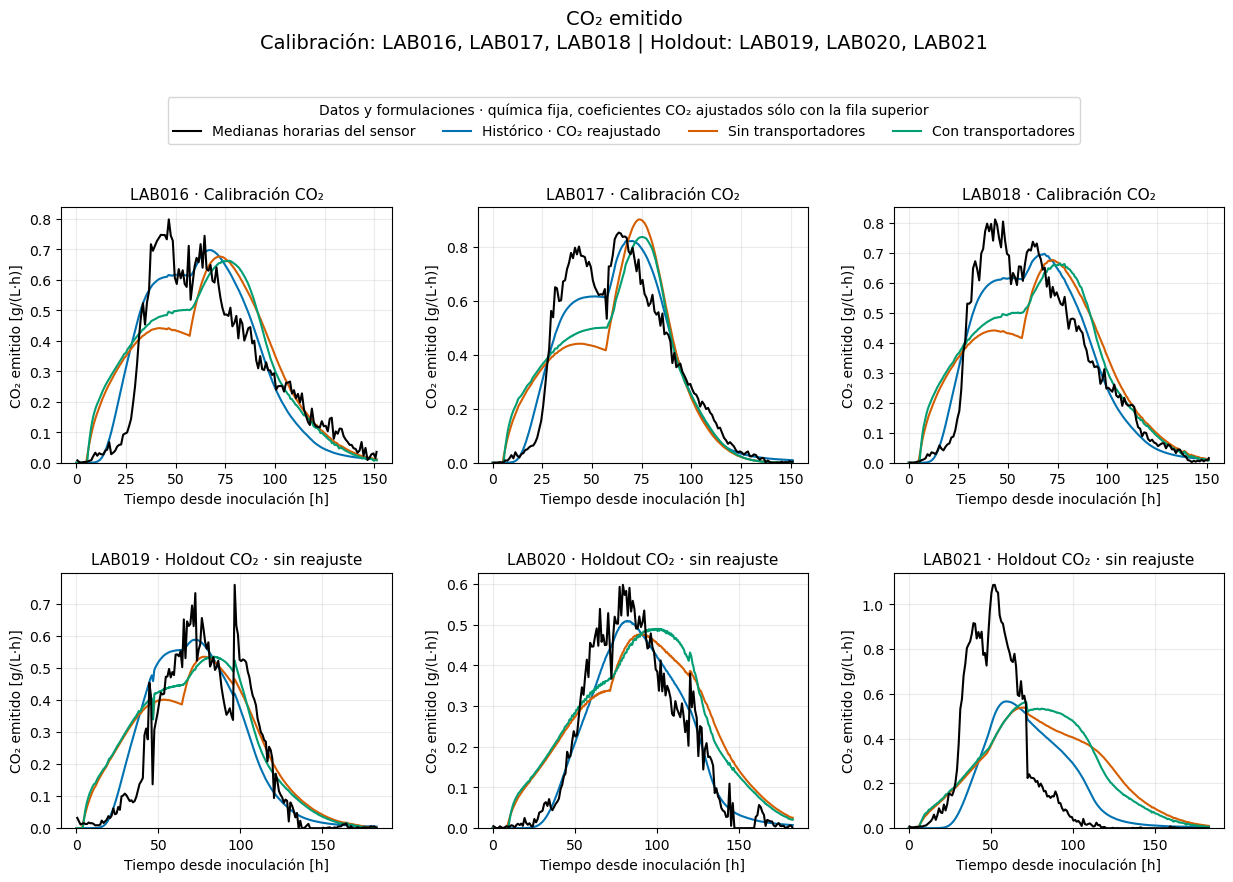

In [3]:
from wine_fermentation.comparison import observations
calibration_observations=observations(result['data'])
colors={'historical':'#0072B2','without_transporters':'#D55E00','with_transporters':'#009E73'}
names={'historical':'Histórico · CO₂ reajustado','without_transporters':'Sin transportadores','with_transporters':'Con transportadores'}
for key,res in experiments.items():
    ordered_labs=res['training_labs']+res['holdout_labs']
    train_label=', '.join(res['training_labs']);holdout_label=', '.join(res['holdout_labs'])
    fig,axes=plt.subplots(2,3,figsize=(15,9))
    fig.subplots_adjust(top=.77,bottom=.08,hspace=.43,wspace=.26)
    fig.suptitle('CO₂ emitido'+'\nCalibración: '+train_label+' | Holdout: '+holdout_label,y=.99,fontsize=14)
    for ax,lab in zip(axes.flat,ordered_labs):
        obs=calibration_observations[lab]
        f=res['curves']['historical',lab]
        obs=obs[obs.time_h.between(f.index.min(),f.index.max())]
        ax.plot(obs.time_h,obs.co2_raw_g_l_h,color='black',lw=1.5,label='Medianas horarias del sensor',zorder=4)
        for name in colors:
            f=res['curves'][name,lab];ax.plot(f.index,f.qpred,color=colors[name],label=names[name])
        split='Calibración CO₂' if lab in res['training_labs'] else 'Holdout CO₂ · sin reajuste'
        ax.set_title(lab+' · '+split,fontsize=11)
        ax.set_ylim(bottom=0);ax.margins(y=.06)
        ax.set_xlabel('Tiempo desde inoculación [h]');ax.set_ylabel('CO₂ emitido [g/(L·h)]');ax.grid(alpha=.25)
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.90),ncol=4,title='Datos y formulaciones · química fija, coeficientes CO₂ ajustados sólo con la fila superior')
    plt.show()

chemical_names={**names,'historical':'Histórico · theta_nv2 fijo'}


## Glucosa + fructosa
Se usa la medición conjunta disponible de G+F; no se exige disponer de glucosa y fructosa individuales ni se imputan resultados ausentes. Las curvas predichas son G+F del modelo. Primero se muestran los ensayos del ajuste químico y después el holdout, sin recalibrar.

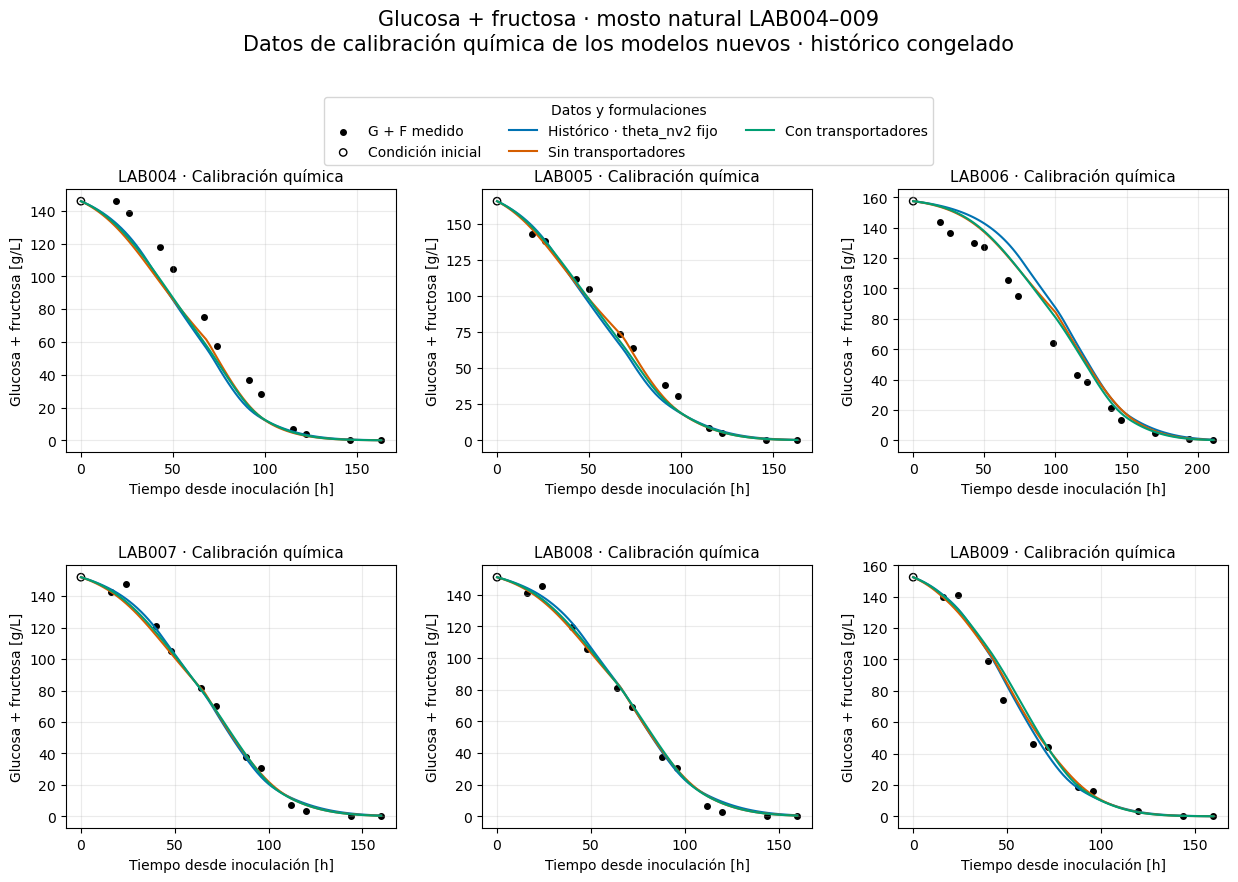

In [4]:
from wine_fermentation.data import natural_batches
from wine_fermentation.shared.simulation import simulate
natural_observations,natural_training_batches,_=natural_batches(ROOT)
chemical_parameters={'historical':json.loads((ROOT/'configs/theta/theta_nv2.json').read_text(encoding='utf-8'))}
for name in ('without_transporters','with_transporters'):
    chemical_parameters[name]=json.loads((ROOT/f'configs/models/{name}/fit.json').read_text(encoding='utf-8'))['parameters']
fig,axes=plt.subplots(2,3,figsize=(15,9))
fig.subplots_adjust(top=.79,bottom=.08,hspace=.43,wspace=.26)
fig.suptitle('Glucosa + fructosa · mosto natural LAB004–009\nDatos de calibración química de los modelos nuevos · histórico congelado',y=.99,fontsize=15)
for ax,batch in zip(axes.flat,natural_training_batches):
    obs=natural_observations.loc[natural_observations.batch.eq(batch.batch)].dropna(subset=['S_GF_g_l'])
    obs=obs.loc[obs.time_h.gt(0)]
    ax.scatter(obs.time_h,obs.S_GF_g_l,color='black',s=16,label='G + F medido')
    ax.scatter([0],[batch.initials['G']+batch.initials['F']],facecolors='none',edgecolors='black',s=28,label='Condición inicial')
    for name in colors:
        f=simulate(name,batch,chemical_parameters[name])
        ax.plot(f.index,f.G+f.F,color=colors[name],label=chemical_names[name])
    ax.set_title(batch.batch+' · Calibración química',fontsize=11)
    ax.set_xlabel('Tiempo desde inoculación [h]');ax.set_ylabel('Glucosa + fructosa [g/L]');ax.grid(alpha=.25)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.90),ncol=3,title='Datos y formulaciones')
plt.show()


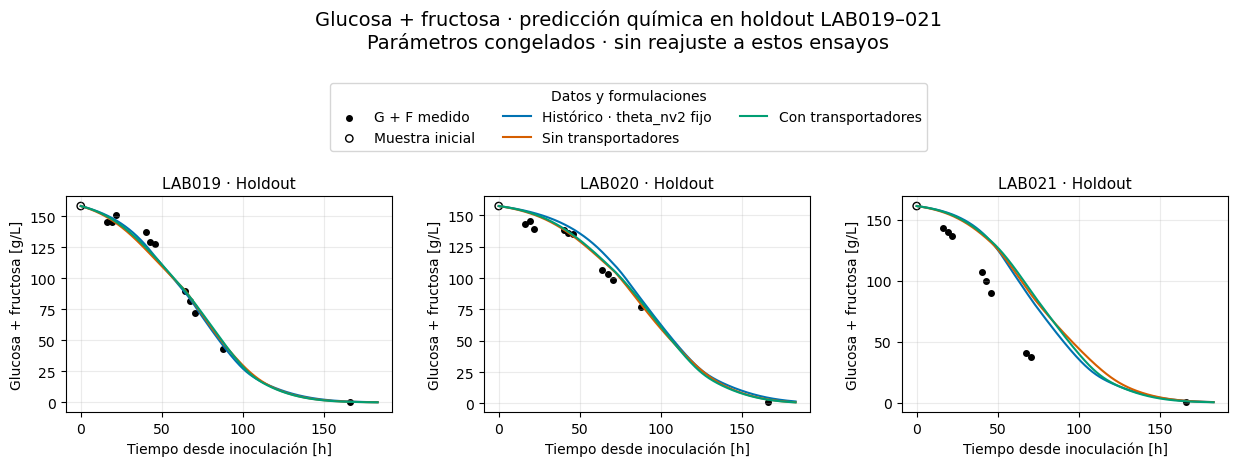

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4.8))
fig.subplots_adjust(top=.60,bottom=.15,wspace=.28)
fig.suptitle('Glucosa + fructosa · predicción química en holdout LAB019–021\nParámetros congelados · sin reajuste a estos ensayos',y=.99,fontsize=14)
for ax,lab in zip(axes,('LAB019','LAB020','LAB021')):
    obs=chemical_observations(result['V'].chem,lab,'GF')
    observed=obs.loc[obs.t_h.gt(0)]
    initial=obs.loc[obs.t_h.le(0)]
    ax.scatter(observed.t_h,observed.GF_g_l,color='black',s=16,label='G + F medido')
    ax.scatter(initial.t_h,initial.GF_g_l,facecolors='none',edgecolors='black',s=28,label='Muestra inicial')
    for name in colors:
        f=result['chemical'][name,lab]
        ax.plot(f.index,f.G+f.F,color=colors[name],label=chemical_names[name])
    ax.set_title(lab+' · Holdout',fontsize=11)
    ax.set_xlabel('Tiempo desde inoculación [h]');ax.set_ylabel('Glucosa + fructosa [g/L]');ax.grid(alpha=.25)
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.85),ncol=3,title='Datos y formulaciones')
plt.show()


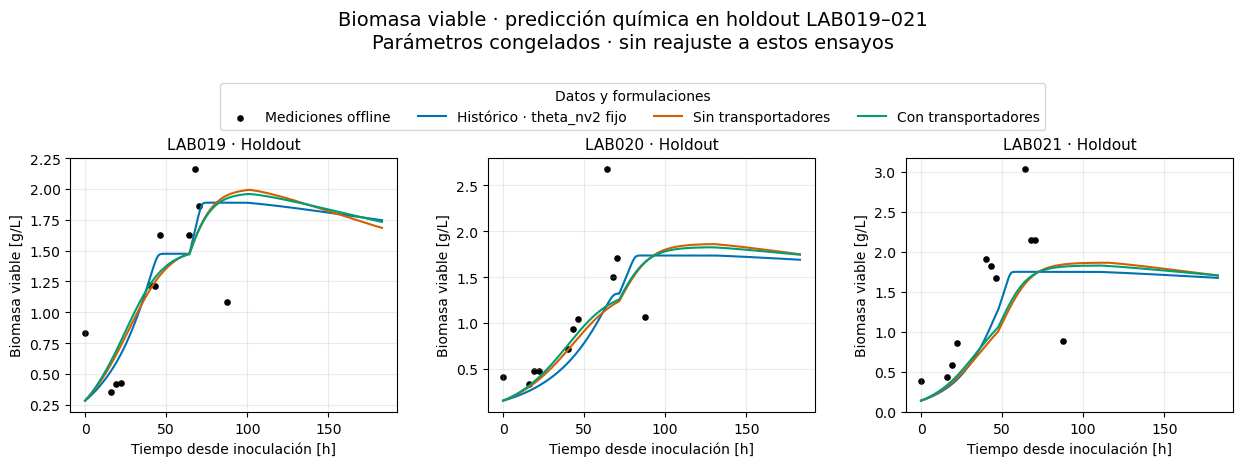

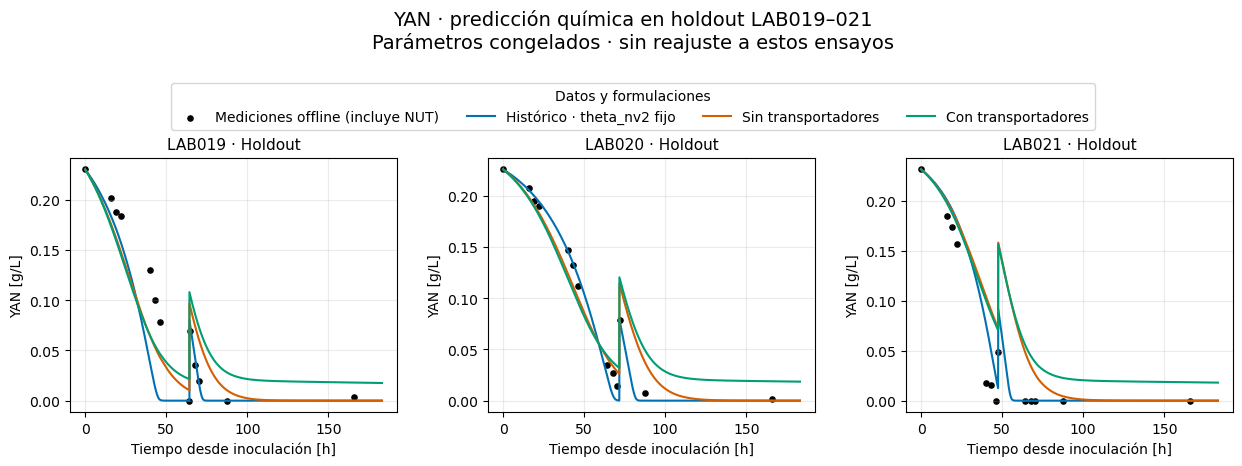

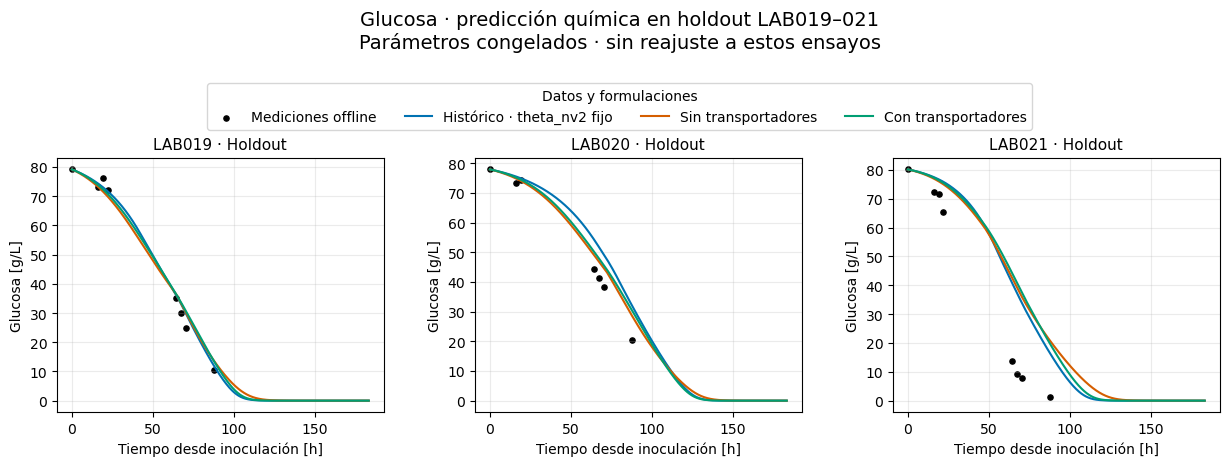

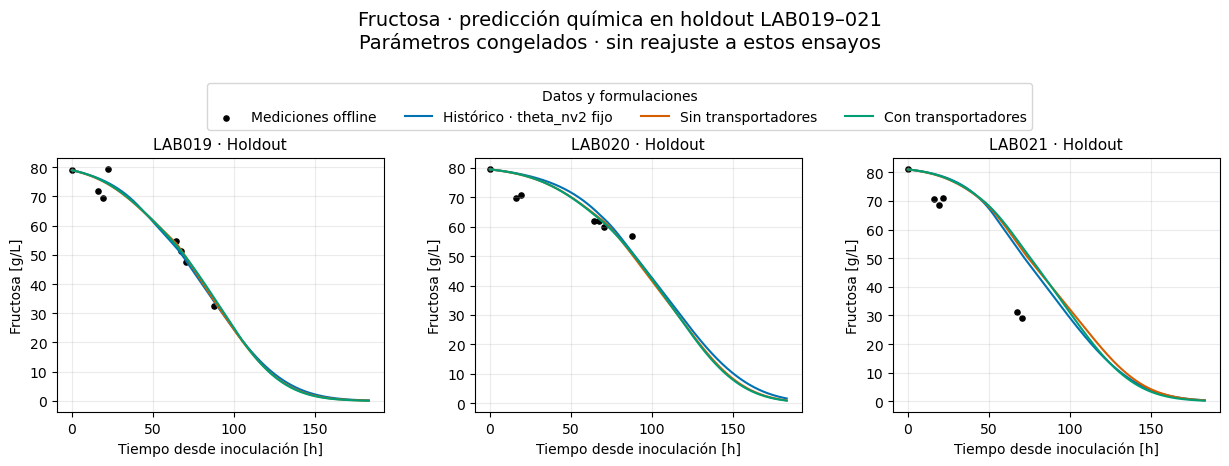

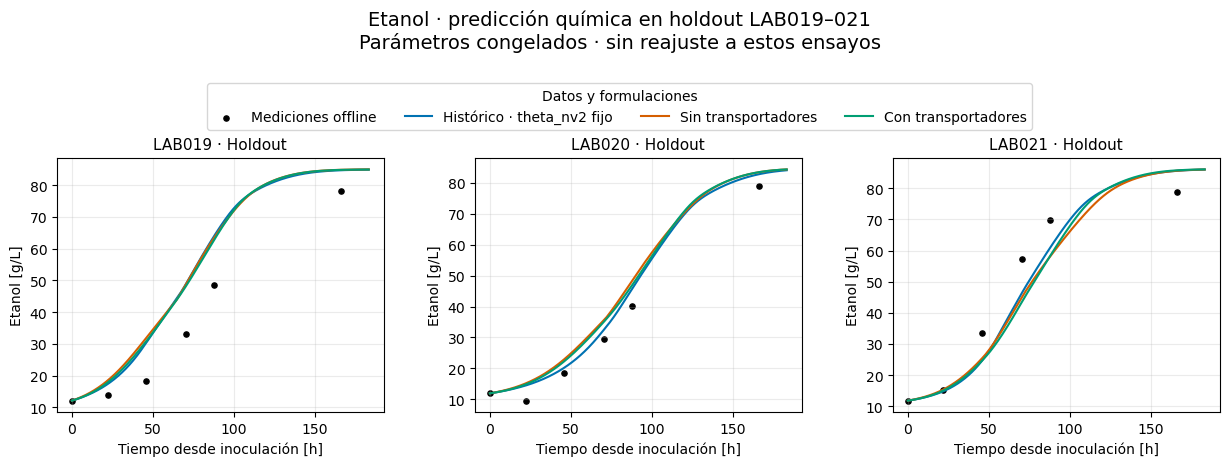

In [6]:
columns={'X':'X_viable_g_l','N':'N_kg_m3','G':'G_g_l','F':'F_g_l','E':'E_g_l'}
state_names={'X':'Biomasa viable','N':'YAN','G':'Glucosa','F':'Fructosa','E':'Etanol'}
for state,col in columns.items():
    fig,axes=plt.subplots(1,3,figsize=(15,4.8))
    fig.subplots_adjust(top=.68,bottom=.15,wspace=.28)
    fig.suptitle(state_names[state]+' · predicción química en holdout LAB019–021\nParámetros congelados · sin reajuste a estos ensayos',y=.99,fontsize=14)
    for ax,lab in zip(axes,('LAB019','LAB020','LAB021')):
        obs=chemical_observations(result['V'].chem,lab,state)
        ax.scatter(obs.t_h,obs[col],color='black',s=14,label='Mediciones offline (incluye NUT)' if state=='N' else 'Mediciones offline')
        for name in colors:
            f=result['chemical'][name,lab];ax.plot(f.index,f[state],color=colors[name],label=chemical_names[name])
        ax.set_title(lab+' · Holdout',fontsize=11)
        ax.set_xlabel('Tiempo desde inoculación [h]');ax.set_ylabel(state_names[state]+' [g/L]');ax.grid(alpha=.25)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.85),ncol=4,title='Datos y formulaciones')
    plt.show()


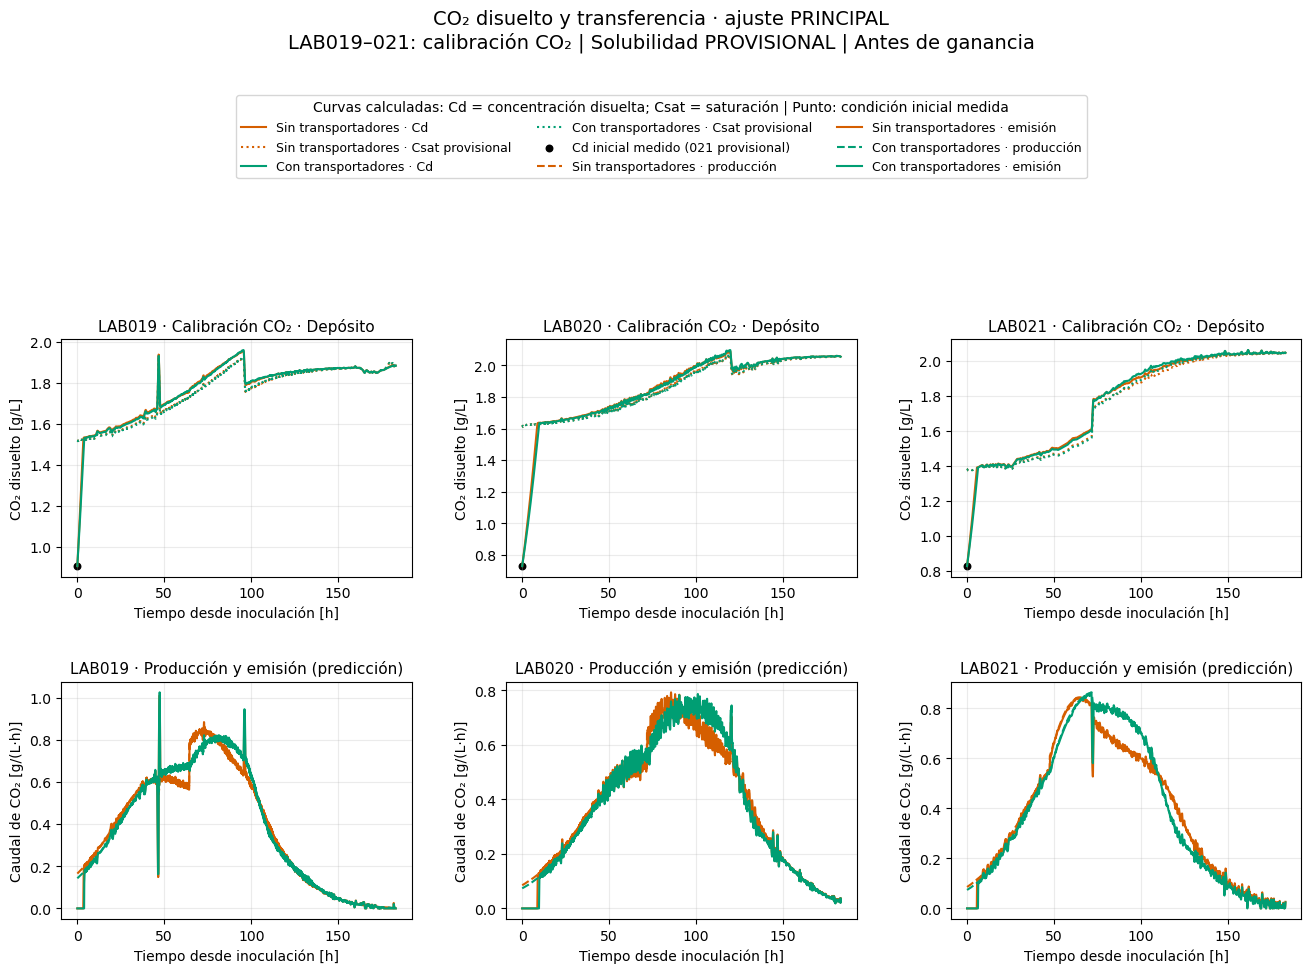

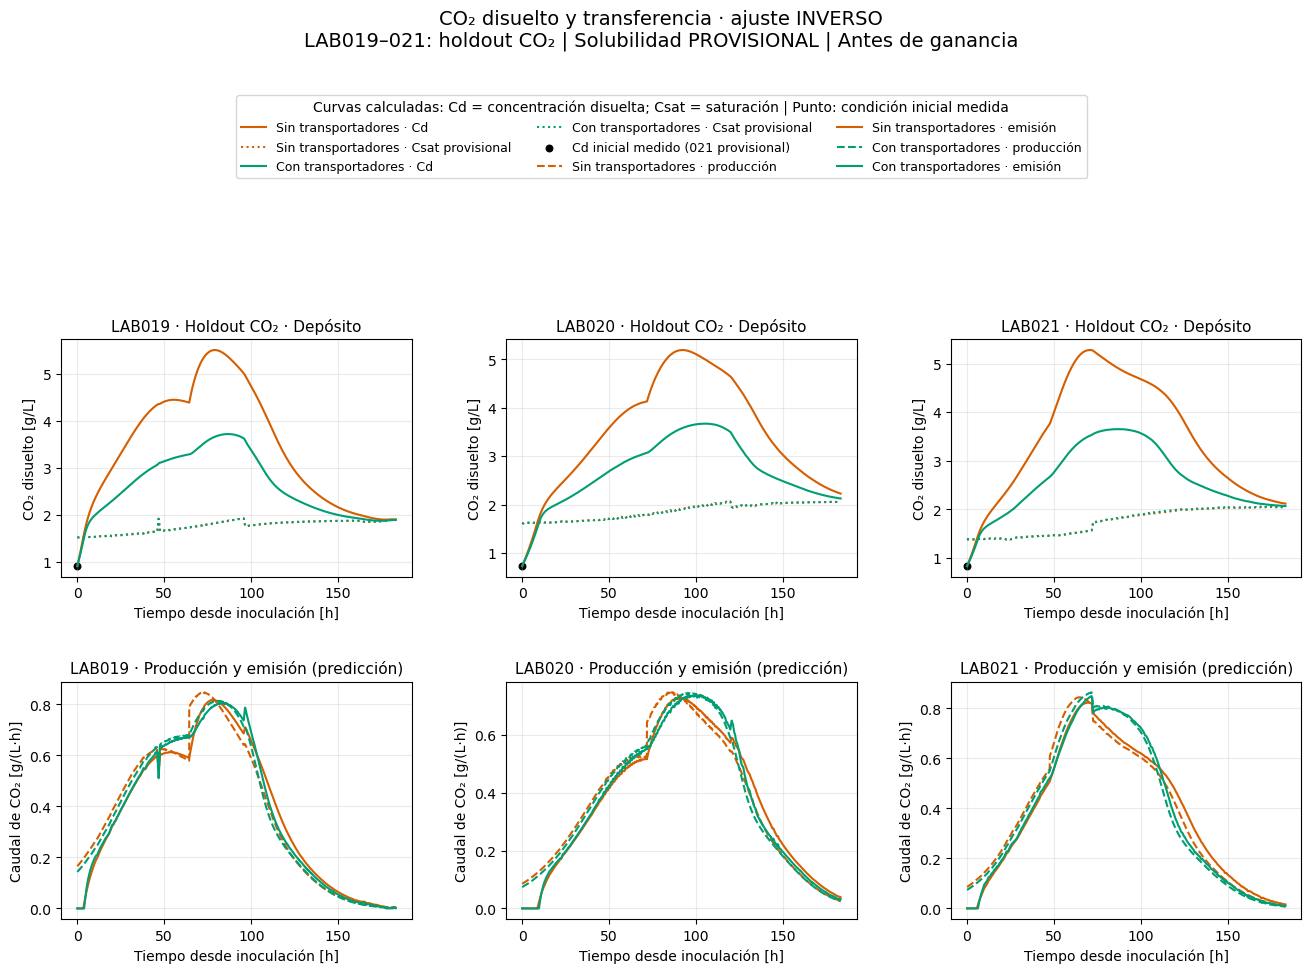

In [7]:
for key,res in experiments.items():
    fig,axes=plt.subplots(2,3,figsize=(16,10))
    fig.subplots_adjust(top=.66,bottom=.08,hspace=.44,wspace=.27)
    fig.suptitle('CO₂ disuelto y transferencia · ajuste '+('PRINCIPAL' if key==PRIMARY_TRAINING else 'INVERSO')+'\nLAB019–021: '+('calibración CO₂' if key==PRIMARY_TRAINING else 'holdout CO₂')+' | Solubilidad PROVISIONAL | Antes de ganancia',y=.99,fontsize=14)
    for j,lab in enumerate(('LAB019','LAB020','LAB021')):
        for name in ('without_transporters','with_transporters'):
            f=res['curves'][name,lab]
            axes[0,j].plot(f.index,f.Cd,color=colors[name],label=names[name]+' · Cd')
            axes[0,j].plot(f.index,f.Csat,color=colors[name],ls=':',label=names[name]+' · Csat provisional')
            axes[1,j].plot(f.index,f.qprod,color=colors[name],ls='--',label=names[name]+' · producción')
            axes[1,j].plot(f.index,f.qgas,color=colors[name],label=names[name]+' · emisión')
        axes[0,j].scatter([0],[{'LAB019':.907,'LAB020':.730,'LAB021':.829}[lab]],color='black',s=22,label='Cd inicial medido (021 provisional)')
        axes[0,j].set_title(lab+' · '+('Calibración CO₂' if lab in res['training_labs'] else 'Holdout CO₂')+' · Depósito',fontsize=11)
        axes[1,j].set_title(lab+' · Producción y emisión (predicción)',fontsize=11)
        for ax in axes[:,j]:ax.set_xlabel('Tiempo desde inoculación [h]');ax.grid(alpha=.25)
        axes[0,j].set_ylabel('CO₂ disuelto [g/L]')
        axes[1,j].set_ylabel('Caudal de CO₂ [g/(L·h)]')
    handles,labels=axes[0,0].get_legend_handles_labels()
    h2,l2=axes[1,0].get_legend_handles_labels()
    fig.legend(handles+h2,labels+l2,loc='upper center',bbox_to_anchor=(.5,.91),ncol=3,title='Curvas calculadas: Cd = concentración disuelta; Csat = saturación | Punto: condición inicial medida',fontsize=9,title_fontsize=10)
    plt.show()
